In [124]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report



In [125]:

df = pd.read_csv("../dataReduction/featurePrep_with_pca.csv")
df.drop('coachID', axis=1, inplace=True)
df.head()





,tmID,year,confID,playoff,lastYearChampion,last_year_pca_1,last_year_pca_2,last_year_pca_3
0,CHA,1,EA,0,0,3.483649,-0.635089,0.014805
1,CLE,1,EA,1,0,3.951787,1.225692,0.292555
2,DET,1,EA,0,0,3.781387,0.498749,0.338893
3,HOU,1,WE,1,0,3.479566,-0.714480,0.200031
4,IND,1,EA,0,0,3.350211,-1.225265,0.113231


In [126]:
min_year = 8
max_year = df['year'].max()
print(max_year)

11


In [127]:
def preprocess_data(df):
    categorical_columns = df.select_dtypes(include=['object']).columns
    for col in categorical_columns:
        if col == 'tmID': 
            continue
        elif col == 'confID': 
            df = pd.get_dummies(df, columns=['confID'], drop_first=False)
        else:
            le = LabelEncoder()
            df[col] = le.fit_transform(df[col])
    
    df['confID_WE'] = df['confID_WE'].astype(int)
    df.drop(['coachID'], axis=1, inplace=True)
    return df

def grid_search_kaggle_submission(df, min_year, max_year):
    df = preprocess_data(df)
    model_metrics = {}
    # Track metrics specifically for years 9 and 10
    years_9_10_metrics = {}
    
    models = {
        'Random Forest': {
            'model': RandomForestClassifier(random_state=42),
            'params': {
                'n_estimators': [50, 100, 200],
                'max_depth': [3, 5, 7, None],
                'min_samples_split': [2, 5, 10],
                'min_samples_leaf': [1, 2, 4]
            }
        },
        'SVM': {
            'model': SVC(random_state=42, probability=True),
            'params': {
                'C': [0.1, 1, 10],
                'kernel': ['rbf', 'linear'],
                'gamma': ['scale', 'auto']
            }
        },
        'Logistic Regression': {
            'model': LogisticRegression(random_state=42),
            'params': {
                'C': [0.1, 1, 10],
                'solver': ['liblinear', 'lbfgs'],
                'max_iter': [1000]
            }
        },
        'KNN': {
            'model': KNeighborsClassifier(),
            'params': {
                'n_neighbors': [3, 5, 7],
                'weights': ['uniform', 'distance'],
                'metric': ['euclidean', 'manhattan']
            }
        },
        'Neural Network': {
            'model': MLPClassifier(random_state=42),
            'params': {
                'hidden_layer_sizes': [(50,), (100,), (50, 50)],
                'activation': ['relu', 'tanh'],
                'solver': ['adam'],
                'alpha': [0.0001, 0.001],
                'max_iter': [1000]
            }
        },
        'Decision Tree': {
            'model': DecisionTreeClassifier(random_state=42),
            'params': {
                'max_depth': [3, 5, 7, None],
                'min_samples_split': [2, 5, 10],
                'min_samples_leaf': [1, 2, 4],
                'criterion': ['gini', 'entropy']
            }
        }
    }

    for year in range(min_year, max_year + 1):
        print(f"\n{'='*20} Processing Year {year} {'='*20}")
        train_data = df[df['year'] < year]
        test_data = df[df['year'] == year]

        X_train = train_data.drop(['playoff', 'tmID'], axis=1)
        y_train = train_data['playoff']
        X_test = test_data.drop(['playoff', 'tmID'], axis=1)
        y_test = test_data['playoff']
        team_ids = test_data['tmID']
        
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        for name, model_info in models.items():
            print(f"\n{'-'*20} Training {name} {'-'*20}")
            
            if name not in model_metrics:
                model_metrics[name] = {
                    'accuracy': [],
                    'precision': [],
                    'recall': [],
                    'f1': []
                }
                years_9_10_metrics[name] = {
                    'accuracy': [],
                    'precision': [],
                    'recall': [],
                    'f1': []
                }
                
            grid_search = GridSearchCV(
                estimator=model_info['model'],
                param_grid=model_info['params'],
                cv=5,
                scoring='f1',
                n_jobs=-1,
                verbose=1
            )

            try:
                grid_search.fit(X_train_scaled, y_train)
                best_model = grid_search.best_estimator_
                
                y_pred = best_model.predict(X_test_scaled)
                y_pred_proba = best_model.predict_proba(X_test_scaled)[:, 1]

                accuracy = accuracy_score(y_test, y_pred)
                precision = precision_score(y_test, y_pred)
                recall = recall_score(y_test, y_pred)
                f1 = f1_score(y_test, y_pred)
                
                model_metrics[name]['accuracy'].append(accuracy)
                model_metrics[name]['precision'].append(precision)
                model_metrics[name]['recall'].append(recall)
                model_metrics[name]['f1'].append(f1)

                # Store metrics for years 9 and 10 separately
                if year >= 9:
                    years_9_10_metrics[name]['accuracy'].append(accuracy)
                    years_9_10_metrics[name]['precision'].append(precision)
                    years_9_10_metrics[name]['recall'].append(recall)
                    years_9_10_metrics[name]['f1'].append(f1)

                print(f"\nMetrics for {name} in year {year}:")
                print(f"Accuracy: {accuracy:.4f}")
                print(f"Precision: {precision:.4f}")
                print(f"Recall: {recall:.4f}")
                print(f"F1 Score: {f1:.4f}")
                print(f"Best parameters: {grid_search.best_params_}")
                print(f"Best cross-validation score: {grid_search.best_score_:.4f}")
                
                submission = pd.DataFrame({
                    'tmID': team_ids,
                    'Playoff': y_pred_proba
                })

                submission['Playoff'] = submission.apply(
                    lambda row: max(row['Playoff'], 0.90) if test_data.loc[test_data['tmID'] == row['tmID'], 'lastYearChampion'].values[0] == 1 else row['Playoff'],
                    axis=1
                )

                submission['Playoff'] = submission['Playoff'].apply(lambda x: "{:.2f}".format(x))
                submission = submission.sort_values(by='tmID')
                filename = f'kaggle_submission_{year}_{name.replace(" ", "_").lower()}.csv'
                submission.to_csv(filename, index=False)
                print(f"Submission saved to {filename}")
                
            except Exception as e:
                print(f"Error training {name}: {str(e)}")
                continue

    # Print overall metrics for each model
    print("\n" + "="*50)
    print("Overall Model Performance Summary (All Years)")
    print("="*50)
    
    for name in models.keys():
        if name in model_metrics:
            print(f"\n{name} Average Metrics:")
            print(f"Accuracy:  {np.mean(model_metrics[name]['accuracy']):.4f} ± {np.std(model_metrics[name]['accuracy']):.4f}")
            print(f"Precision: {np.mean(model_metrics[name]['precision']):.4f} ± {np.std(model_metrics[name]['precision']):.4f}")
            print(f"Recall:    {np.mean(model_metrics[name]['recall']):.4f} ± {np.std(model_metrics[name]['recall']):.4f}")
            print(f"F1 Score:  {np.mean(model_metrics[name]['f1']):.4f} ± {np.std(model_metrics[name]['f1']):.4f}")

    # Print metrics specifically for years 9 and 10
    print("\n" + "="*50)
    print("Model Performance Summary (Years 9 and 10 Only)")
    print("="*50)
    
    for name in models.keys():
        if name in years_9_10_metrics:
            print(f"\n{name} Average Metrics (Years 9-10):")
            print(f"Accuracy:  {np.mean(years_9_10_metrics[name]['accuracy']):.4f} ± {np.std(years_9_10_metrics[name]['accuracy']):.4f}")
            print(f"Precision: {np.mean(years_9_10_metrics[name]['precision']):.4f} ± {np.std(years_9_10_metrics[name]['precision']):.4f}")
            print(f"Recall:    {np.mean(years_9_10_metrics[name]['recall']):.4f} ± {np.std(years_9_10_metrics[name]['recall']):.4f}")
            print(f"F1 Score:  {np.mean(years_9_10_metrics[name]['f1']):.4f} ± {np.std(years_9_10_metrics[name]['f1']):.4f}")

df = pd.read_csv("../dataReduction/featurePrep_with_pca.csv")
min_year = 9
max_year = 10
grid_search_kaggle_submission(df, min_year, max_year)


==================== Processing Year 9 ====================

-------------------- Training Random Forest --------------------
Fitting 5 folds for each of 108 candidates, totalling 540 fits

Metrics for Random Forest in year 9:
Accuracy: 0.8571
Precision: 0.8000
Recall: 1.0000
F1 Score: 0.8889
Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best cross-validation score: 0.6537
Submission saved to kaggle_submission_9_random_forest.csv

-------------------- Training SVM --------------------
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Metrics for SVM in year 9:
Accuracy: 0.5714
Precision: 0.5714
Recall: 1.0000
F1 Score: 0.7273
Best parameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}
Best cross-validation score: 0.7149
Submission saved to kaggle_submission_9_svm.csv

-------------------- Training Logistic Regression --------------------
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Metrics for Lo

In [128]:
import pandas as pd

comparison_data = []
metrics = ['accuracy', 'precision', 'recall', 'f1']

for model, metric_values in model_metrics.items():
    for metric in metrics:
        for i, year in enumerate([9, 10]):  # Year 9 is at index `-2`, Year 10 at `-1`
            comparison_data.append({
                'Model': model,
                'Year': year,
                'Metric': metric,
                'Value': metric_values[metric][-2 + i]  # Access years 9 and 10
            })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df)


                  Model  Year     Metric     Value
0         Random Forest     9   accuracy  0.714286
1         Random Forest    10   accuracy  0.538462
2         Random Forest     9  precision  0.666667
3         Random Forest    10  precision  0.600000
4         Random Forest     9     recall  1.000000
5         Random Forest    10     recall  0.750000
6         Random Forest     9         f1  0.800000
7         Random Forest    10         f1  0.666667
8                   SVM     9   accuracy  0.571429
9                   SVM    10   accuracy  0.615385
10                  SVM     9  precision  0.571429
11                  SVM    10  precision  0.615385
12                  SVM     9     recall  1.000000
13                  SVM    10     recall  1.000000
14                  SVM     9         f1  0.727273
15                  SVM    10         f1  0.761905
16  Logistic Regression     9   accuracy  0.642857
17  Logistic Regression    10   accuracy  0.615385
18  Logistic Regression     9  

C:\Users\jpaso\AppData\Local\Temp\ipykernel_13756\3309445043.py:30: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


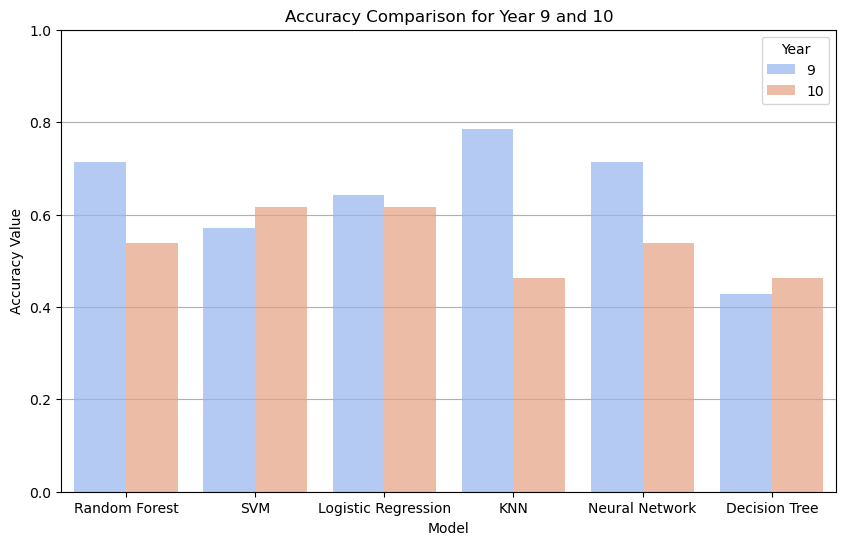

C:\Users\jpaso\AppData\Local\Temp\ipykernel_13756\3309445043.py:30: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


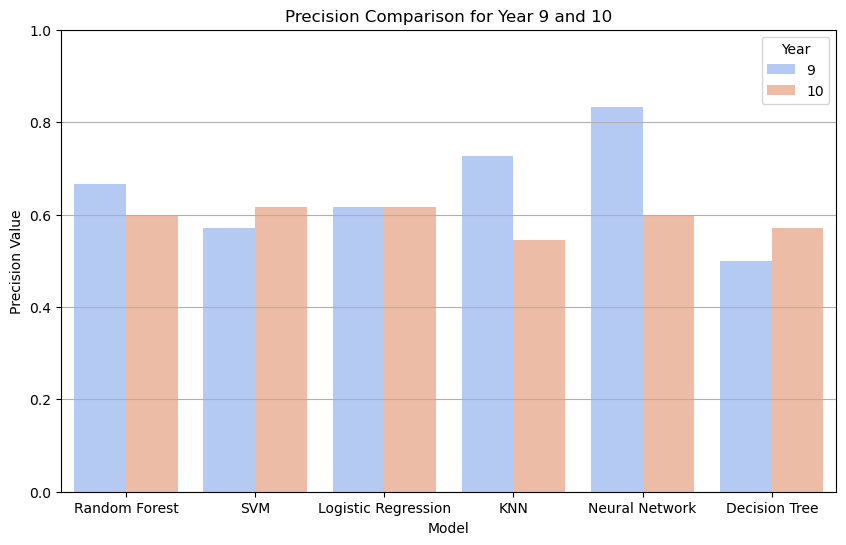

C:\Users\jpaso\AppData\Local\Temp\ipykernel_13756\3309445043.py:30: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


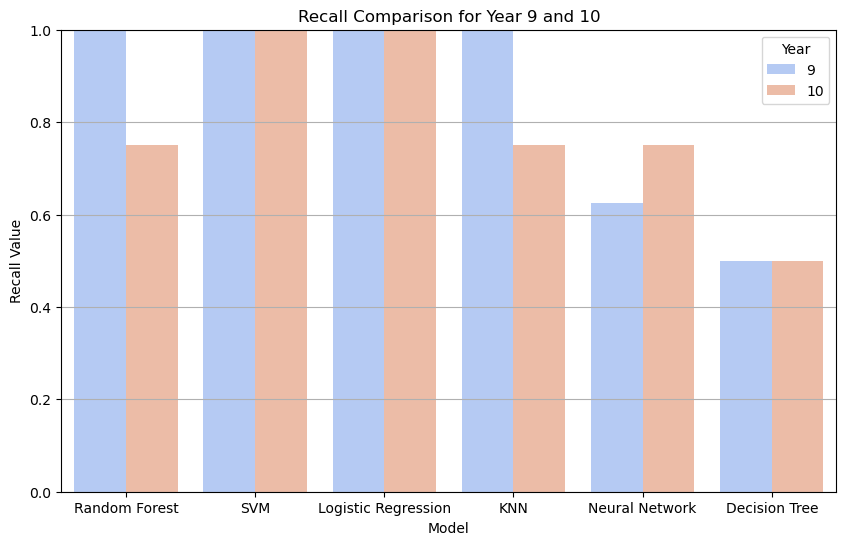

C:\Users\jpaso\AppData\Local\Temp\ipykernel_13756\3309445043.py:30: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


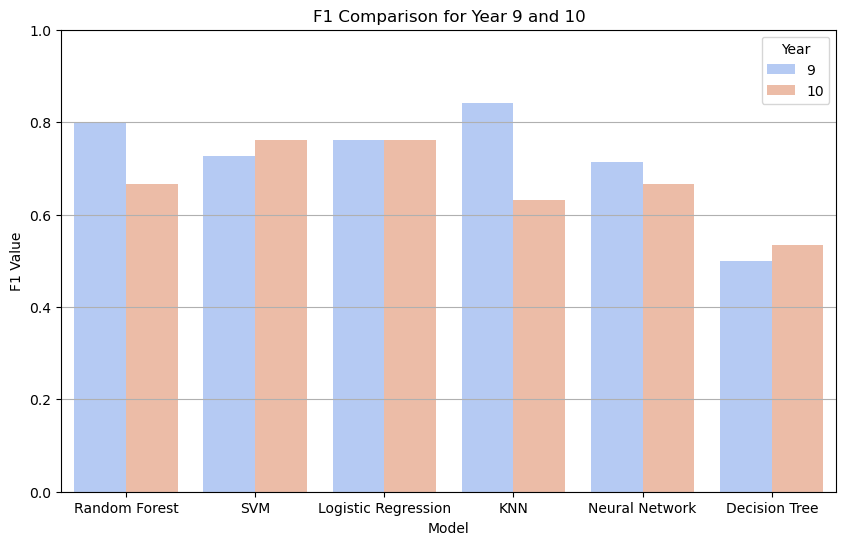

In [133]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Extract data from model_metrics dynamically
comparison_data = []
metrics = ['accuracy', 'precision', 'recall', 'f1']  # Metrics we are comparing

for model, metric_values in model_metrics.items():
    for metric in metrics:
        # Extract years 9 and 10 data from the metric
        for year_offset, year in enumerate([9, 10], start=-2):
            value = metric_values[metric][year_offset]
            comparison_data.append({
                'Model': model,
                'Year': year,
                'Metric': metric,
                'Value': value
            })

# Convert to DataFrame
comparison_df = pd.DataFrame(comparison_data)

# Generate a plot for each metric dynamically
metrics = comparison_df['Metric'].unique()

for metric in metrics:
    plt.figure(figsize=(10, 6))
    metric_df = comparison_df[comparison_df['Metric'] == metric]
    sns.barplot(
        data=metric_df,
        x='Model',
        y='Value',
        hue='Year',
        palette='coolwarm',
        ci=None
    )
    plt.title(f'{metric.capitalize()} Comparison for Year 9 and 10')
    plt.xlabel('Model')
    plt.ylabel(f'{metric.capitalize()} Value')
    plt.legend(title='Year')
    plt.ylim(0, 1)  # Assuming metric values are between 0 and 1
    plt.grid(axis='y')
    plt.show()


In [130]:
def preprocess_data(df):
    categorical_columns = df.select_dtypes(include=['object']).columns

    for col in categorical_columns:
        if col == 'tmID': 
            continue
        elif col == 'confID': 
            df = pd.get_dummies(df, columns=['confID'], drop_first=False)
        else:
            le = LabelEncoder()
            df[col] = le.fit_transform(df[col])
    
    df['confID_WE'] = df['confID_WE'].astype(int)
    df.drop(['coachID'], axis=1, inplace=True)
    
    return df


def grid_search_models(df, min_year, max_year):
    df = preprocess_data(df)
    models = {
        'Random Forest': {
            'model': RandomForestClassifier(random_state=42),
            'params': {
                'n_estimators': [50, 100, 200],
                'max_depth': [3, 5, 7, None],
                'min_samples_split': [2, 5, 10],
                'min_samples_leaf': [1, 2, 4]
            }
        },
        'SVC': {
            'model': SVC(random_state=42, probability=True),
            'params': {
                'C': [0.1, 1, 10, 100],
                'kernel': ['rbf', 'linear'],
                'gamma': ['scale', 'auto']
            }
        }
    }

    for year in range(min_year, max_year + 1):
        print(f"\n--- Processing Year {year} ---")
        train_data = df[df['year'] < year]
        test_data = df[df['year'] == year]

        X_train = train_data.drop(['playoff'], axis=1)
        y_train = train_data['playoff']
        X_test = test_data.drop(['playoff'], axis=1)
        y_test = test_data['playoff']
        team_ids = test_data['tmID']
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train.drop(['tmID'], axis=1))
        X_test_scaled = scaler.transform(X_test.drop(['tmID'], axis=1))

        for name, model_info in models.items():
            print(f"\nGrid Search for {name}")
            grid_search = GridSearchCV(
                estimator=model_info['model'],
                param_grid=model_info['params'],
                cv=5,
                scoring='f1',
                n_jobs=-1
            )

            grid_search.fit(X_train_scaled, y_train)
            best_model = grid_search.best_estimator_
            y_pred_proba = best_model.predict_proba(X_test_scaled)[:, 1]
            
            # Use .loc to modify the DataFrame properly
            test_data.loc[:, 'predicted_proba'] = y_pred_proba
            
            selected_teams = []
            for conf in ['EA', 'WE']:
                conference_teams = test_data[test_data[f'confID_{conf}'] == 1]
                top_teams = conference_teams.nlargest(4, 'predicted_proba')
                selected_teams.extend(top_teams.index)

            # Use .loc to set the final prediction correctly
            test_data.loc[:, 'final_prediction'] = 0
            test_data.loc[selected_teams, 'final_prediction'] = 1
            
            predictions = pd.DataFrame({
                'year': year,
                'tmID': team_ids,
                'predicted_proba': y_pred_proba,
                'final_prediction': test_data['final_prediction']
            })

            if name in ['Random Forest', 'SVC']:
                filename = f'predictions_{year}_{name.replace(" ", "_")}.csv'
                predictions.to_csv(filename, index=False)
                print(f"Predictions for {name} in year {year} saved to {filename}")

df = pd.read_csv("../dataReduction/featurePrep_with_pca.csv")

min_year = 9
max_year = df['year'].max()
grid_search_models(df, min_year, max_year)




--- Processing Year 9 ---

Grid Search for Random Forest


C:\Users\jpaso\AppData\Local\Temp\ipykernel_13756\1478290888.py:70: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data.loc[:, 'predicted_proba'] = y_pred_proba
C:\Users\jpaso\AppData\Local\Temp\ipykernel_13756\1478290888.py:79: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data.loc[:, 'final_prediction'] = 0


Predictions for Random Forest in year 9 saved to predictions_9_Random_Forest.csv

Grid Search for SVC
Predictions for SVC in year 9 saved to predictions_9_SVC.csv

--- Processing Year 10 ---

Grid Search for Random Forest


C:\Users\jpaso\AppData\Local\Temp\ipykernel_13756\1478290888.py:70: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data.loc[:, 'predicted_proba'] = y_pred_proba
C:\Users\jpaso\AppData\Local\Temp\ipykernel_13756\1478290888.py:79: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data.loc[:, 'final_prediction'] = 0


Predictions for Random Forest in year 10 saved to predictions_10_Random_Forest.csv

Grid Search for SVC
Predictions for SVC in year 10 saved to predictions_10_SVC.csv

--- Processing Year 11 ---

Grid Search for Random Forest


C:\Users\jpaso\AppData\Local\Temp\ipykernel_13756\1478290888.py:70: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data.loc[:, 'predicted_proba'] = y_pred_proba
C:\Users\jpaso\AppData\Local\Temp\ipykernel_13756\1478290888.py:79: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data.loc[:, 'final_prediction'] = 0


Predictions for Random Forest in year 11 saved to predictions_11_Random_Forest.csv

Grid Search for SVC
Predictions for SVC in year 11 saved to predictions_11_SVC.csv


In [131]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

def classify_and_evaluate(df, min_year, max_year, param_list):
    all_year_results = {}
    for year in range(min_year, max_year + 1):
        train_data = df[df['year'] < year]
        test_data = df[df['year'] == year]
        
        X_train = train_data.drop(['playoff'], axis=1)  
        y_train = train_data['playoff']
        
        X_test = test_data.drop(['playoff'], axis=1)
        y_test = test_data['playoff']
        
        model = param_list['model']

        model.set_params(**param_list['model_params'])
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        accuracy = accuracy_score(y_test, y_pred)
        conf_matrix = confusion_matrix(y_test, y_pred)
        class_report = classification_report(y_test, y_pred)
        
        # Calculate precision, recall, and F1 score
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        
        all_year_results[year] = {
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1': f1,
            'conf_matrix': conf_matrix,
            'class_report': class_report,
            'actual': y_test.values,
            'predicted': y_pred
        }

    return all_year_results



# Decision Tree

In [132]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

# Define a function to preprocess data by encoding categorical columns
def preprocess_data(df):
    categorical_columns = df.select_dtypes(include=['object']).columns
    le = LabelEncoder()  # Initialize the label encoder
    
    for col in categorical_columns:
        if col == 'tmID':  # Ignore team ID or any other column that is not relevant for encoding
            continue
        df[col] = le.fit_transform(df[col])  # Apply label encoding to categorical columns
    
    return df

# Preprocess the data
df = preprocess_data(df)

# Now, param_list with DecisionTreeClassifier
random_state = 42
param_list = {
    'model': DecisionTreeClassifier(random_state=random_state),
    'model_params': {
        'criterion': 'gini',
        'max_depth': 5,
        'min_samples_split': 10,
        'min_samples_leaf': 4,
        'max_features': 'sqrt',
        'splitter': 'best',
        'min_impurity_decrease': 0.0
    }
}

# Assuming `classify_and_evaluate` function exists to train and evaluate the model
all_year_results = classify_and_evaluate(df, min_year, max_year, param_list)

# Calculating mean metrics across all years
mean_accuracy = 0
mean_precision = 0
mean_recall = 0
mean_f1 = 0

# Iterate through the results and accumulate metrics
for year, results in all_year_results.items():
    print(f"Year {year}:")
    print("Accuracy:", results['accuracy'])
    print("Precision:", results['precision'])
    print("Recall:", results['recall'])
    print("F1 Score:", results['f1'])
    print("Confusion Matrix:\n", results['conf_matrix'])
    print("Classification Report:\n", results['class_report'])
    print("Actual:", results['actual'])
    print("Predicted:", results['predicted'])
    print("-" * 50)
    
    mean_accuracy += results['accuracy']
    mean_precision += results['precision']
    mean_recall += results['recall']
    mean_f1 += results['f1']

# Calculate the mean values across all years
num_years = len(all_year_results)
mean_accuracy /= num_years
mean_precision /= num_years
mean_recall /= num_years
mean_f1 /= num_years

# Print the mean values
print("Mean Accuracy:", mean_accuracy)
print("Mean Precision:", mean_precision)
print("Mean Recall:", mean_recall)
print("Mean F1 Score:", mean_f1)


ValueError: could not convert string to float: 'CHA'

# SVC


In [ ]:
from sklearn.svm import SVC

param_list = {
    'model': SVC(random_state=random_state),
    'model_params': {
        'C': 1.0,
        'kernel': 'rbf',
        'degree': 3,
        'gamma': 'scale'
    }
}


all_year_results = classify_and_evaluate(df, min_year, max_year, param_list)    
mean_accuracy = 0
mean_precision = 0
mean_recall = 0
mean_f1 = 0

for year, results in all_year_results.items():
    print(f"Year {year}:")
    print("Accuracy:", results['accuracy'])
    print("Precision:", results['precision'])
    print("Recall:", results['recall'])
    print("F1 Score:", results['f1'])
    print("Confusion Matrix:\n", results['conf_matrix'])
    print("Classification Report:\n", results['class_report'])
    print("Actual:", results['actual'])
    print("Predicted:", results['predicted'])
    print("-" * 50)
    
    mean_accuracy += results['accuracy']
    mean_precision += results['precision']
    mean_recall += results['recall']
    mean_f1 += results['f1']


num_years = len(all_year_results)
mean_accuracy /= num_years
mean_precision /= num_years
mean_recall /= num_years
mean_f1 /= num_years


print("Mean Accuracy:", mean_accuracy)
print("Mean Precision:", mean_precision)
print("Mean Recall:", mean_recall)
print("Mean F1 Score:", mean_f1)


# Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

param_list = {
    'model': LogisticRegression(random_state=random_state),
    'model_params': {
        'solver': 'liblinear', 
        'C': 1.0, 
        'max_iter': 1000 
    }
}

all_year_results = classify_and_evaluate(df, min_year, max_year, param_list)    
mean_accuracy = 0
mean_precision = 0
mean_recall = 0
mean_f1 = 0

for year, results in all_year_results.items():
    print(f"Year {year}:")
    print("Accuracy:", results['accuracy'])
    print("Precision:", results['precision'])
    print("Recall:", results['recall'])
    print("F1 Score:", results['f1'])
    print("Confusion Matrix:\n", results['conf_matrix'])
    print("Classification Report:\n", results['class_report'])
    print("Actual:", results['actual'])
    print("Predicted:", results['predicted'])
    print("-" * 50)
    
    mean_accuracy += results['accuracy']
    mean_precision += results['precision']
    mean_recall += results['recall']
    mean_f1 += results['f1']


num_years = len(all_year_results)
mean_accuracy /= num_years
mean_precision /= num_years
mean_recall /= num_years
mean_f1 /= num_years


print("Mean Accuracy:", mean_accuracy)
print("Mean Precision:", mean_precision)
print("Mean Recall:", mean_recall)
print("Mean F1 Score:", mean_f1)


# Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

param_list = {
    'model': RandomForestClassifier(random_state=random_state),
    'model_params': {
        'n_estimators': 100, 
        'max_depth': 5,      
        'min_samples_split': 10 
    }
}

all_year_results = classify_and_evaluate(df, min_year, max_year, param_list)    
mean_accuracy = 0
mean_precision = 0
mean_recall = 0
mean_f1 = 0

for year, results in all_year_results.items():
    print(f"Year {year}:")
    print("Accuracy:", results['accuracy'])
    print("Precision:", results['precision'])
    print("Recall:", results['recall'])
    print("F1 Score:", results['f1'])
    print("Confusion Matrix:\n", results['conf_matrix'])
    print("Classification Report:\n", results['class_report'])
    print("Actual:", results['actual'])
    print("Predicted:", results['predicted'])
    print("-" * 50)
    
    mean_accuracy += results['accuracy']
    mean_precision += results['precision']
    mean_recall += results['recall']
    mean_f1 += results['f1']


num_years = len(all_year_results)
mean_accuracy /= num_years
mean_precision /= num_years
mean_recall /= num_years
mean_f1 /= num_years


print("Mean Accuracy:", mean_accuracy)
print("Mean Precision:", mean_precision)
print("Mean Recall:", mean_recall)
print("Mean F1 Score:", mean_f1)


# KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

param_list = {
    'model': KNeighborsClassifier(),
    'model_params': {
        'n_neighbors': 5, 
        'weights': 'uniform', 
        'metric': 'minkowski' 
    }
}

all_year_results = classify_and_evaluate(df, min_year, max_year, param_list)    
mean_accuracy = 0
mean_precision = 0
mean_recall = 0
mean_f1 = 0

for year, results in all_year_results.items():
    print(f"Year {year}:")
    print("Accuracy:", results['accuracy'])
    print("Precision:", results['precision'])
    print("Recall:", results['recall'])
    print("F1 Score:", results['f1'])
    print("Confusion Matrix:\n", results['conf_matrix'])
    print("Classification Report:\n", results['class_report'])
    print("Actual:", results['actual'])
    print("Predicted:", results['predicted'])
    print("-" * 50)
    
    mean_accuracy += results['accuracy']
    mean_precision += results['precision']
    mean_recall += results['recall']
    mean_f1 += results['f1']


num_years = len(all_year_results)
mean_accuracy /= num_years
mean_precision /= num_years
mean_recall /= num_years
mean_f1 /= num_years


print("Mean Accuracy:", mean_accuracy)
print("Mean Precision:", mean_precision)
print("Mean Recall:", mean_recall)
print("Mean F1 Score:", mean_f1)



# Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

param_list = {
    'model': GradientBoostingClassifier(random_state=random_state),
    'model_params': {
        'n_estimators': 100,  
        'learning_rate': 0.1,
        'max_depth': 3, 
        'subsample': 0.9  
    }
}

all_year_results = classify_and_evaluate(df, min_year, max_year, param_list)    
mean_accuracy = 0
mean_precision = 0
mean_recall = 0
mean_f1 = 0

for year, results in all_year_results.items():
    print(f"Year {year}:")
    print("Accuracy:", results['accuracy'])
    print("Precision:", results['precision'])
    print("Recall:", results['recall'])
    print("F1 Score:", results['f1'])
    print("Confusion Matrix:\n", results['conf_matrix'])
    print("Classification Report:\n", results['class_report'])
    print("Actual:", results['actual'])
    print("Predicted:", results['predicted'])
    print("-" * 50)
    
    mean_accuracy += results['accuracy']
    mean_precision += results['precision']
    mean_recall += results['recall']
    mean_f1 += results['f1']


num_years = len(all_year_results)
mean_accuracy /= num_years
mean_precision /= num_years
mean_recall /= num_years
mean_f1 /= num_years


print("Mean Accuracy:", mean_accuracy)
print("Mean Precision:", mean_precision)
print("Mean Recall:", mean_recall)
print("Mean F1 Score:", mean_f1)



# Neural Network

In [ ]:
from sklearn.neural_network import MLPClassifier

param_list = {
    'model': MLPClassifier(random_state=random_state, max_iter=500),  
    'model_params': {
        'hidden_layer_sizes': (100,), 
        'activation': 'relu',         
        'solver': 'adam',            
        'alpha': 0.0001,              
        'learning_rate': 'adaptive', 
        'early_stopping': True,       
    }
}

all_year_results = classify_and_evaluate(df, min_year, max_year, param_list)
mean_accuracy = 0
mean_precision = 0
mean_recall = 0
mean_f1 = 0

for year, results in all_year_results.items():
    print(f"Year {year}:")
    print("Accuracy:", results['accuracy'])
    print("Precision:", results['precision'])
    print("Recall:", results['recall'])
    print("F1 Score:", results['f1'])
    print("Confusion Matrix:\n", results['conf_matrix'])
    print("Classification Report:\n", results['class_report'])
    print("Actual:", results['actual'])
    print("Predicted:", results['predicted'])
    print("-" * 50)
    
    mean_accuracy += results['accuracy']
    mean_precision += results['precision']
    mean_recall += results['recall']
    mean_f1 += results['f1']


num_years = len(all_year_results)
mean_accuracy /= num_years
mean_precision /= num_years
mean_recall /= num_years
mean_f1 /= num_years


print("Mean Accuracy:", mean_accuracy)
print("Mean Precision:", mean_precision)
print("Mean Recall:", mean_recall)
print("Mean F1 Score:", mean_f1)



In [ ]:
from sklearn.naive_bayes import GaussianNB

param_list = {
    'model': GaussianNB(),
    'model_params': {
        'var_smoothing': 1e-6
    }
}

all_year_results = classify_and_evaluate(df, min_year, max_year, param_list)

mean_accuracy = 0
mean_precision = 0
mean_recall = 0
mean_f1 = 0

for year, results in all_year_results.items():
    print(f"Year {year}:")
    print("Accuracy:", results['accuracy'])
    print("Precision:", results['precision'])
    print("Recall:", results['recall'])
    print("F1 Score:", results['f1'])
    print("Confusion Matrix:\n", results['conf_matrix'])
    print("Classification Report:\n", results['class_report'])
    print("Actual:", results['actual'])
    print("Predicted:", results['predicted'])
    print("-" * 50)
    
    mean_accuracy += results['accuracy']
    mean_precision += results['precision']
    mean_recall += results['recall']
    mean_f1 += results['f1']


num_years = len(all_year_results)
mean_accuracy /= num_years
mean_precision /= num_years
mean_recall /= num_years
mean_f1 /= num_years


print("Mean Accuracy:", mean_accuracy)
print("Mean Precision:", mean_precision)
print("Mean Recall:", mean_recall)
print("Mean F1 Score:", mean_f1)

